# Discrimination, calibration and stability

These cells were executed against the real project outputs. The complete training
and SQL implementation is in the linked source modules. This walkthrough reads and
verifies executed artifacts rather than silently retraining the expensive models.
Home Credit is a consumer-lending proxy; validation is random holdout, never true OOT.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
if not (ROOT/'reports/metrics.json').exists():
    ROOT=ROOT.parent
metrics=json.loads((ROOT/'reports/metrics.json').read_text())


## Actual validation tables

scorecard


,rows,bad_count,bad_rate,auc,gini,ks,brier,log_loss,mean_predicted_pd
train,147604.0,11916.0,0.080730,0.754688,0.509377,0.383378,0.068248,0.247601,0.080674
calibration,36902.0,2979.0,0.080727,0.748094,0.496188,0.369597,0.068286,0.248720,0.080504
test,61502.0,4965.0,0.080729,0.755518,0.511037,0.383664,0.068261,0.247474,0.080680
holdout,61503.0,4965.0,0.080728,0.751939,0.503879,0.376351,0.068561,0.248630,0.080736


lightgbm


,rows,bad_count,bad_rate,auc,gini,ks,brier,log_loss,mean_predicted_pd
train,147604.0,11916.0,0.080730,0.835966,0.671931,0.511162,0.061538,0.219400,0.080623
calibration,36902.0,2979.0,0.080727,0.775546,0.551093,0.414702,0.066494,0.240396,0.079853
test,61502.0,4965.0,0.080729,0.784773,0.569546,0.435021,0.066011,0.237814,0.080555
holdout,61503.0,4965.0,0.080728,0.781318,0.562635,0.428091,0.066526,0.239492,0.080595


,decile,rows,bads,min_pd,max_pd,goods,bad_rate,cumulative_bad_share,cumulative_good_share,ks_at_decile,cumulative_lift
0,1,6151,1582,0.178172,0.718066,4569,0.257194,0.318630,0.080813,0.237818,3.185942
1,2,6150,903,0.121542,0.178148,5247,0.146829,0.500504,0.173618,0.326886,2.502436
2,3,6150,680,0.090612,0.121536,5470,0.110569,0.637462,0.270367,0.367095,2.124863
3,4,6150,532,0.070013,0.090600,5618,0.086504,0.744612,0.369734,0.374879,1.861546
4,5,6151,399,0.054818,0.070011,5752,0.064868,0.824975,0.471471,0.353504,1.649923
5,6,6150,284,0.043048,0.054817,5866,0.046179,0.882175,0.575224,0.306951,1.470284
6,7,6150,226,0.033523,0.043047,5924,0.036748,0.927694,0.680003,0.247691,1.325280
7,8,6150,173,0.025065,0.033521,5977,0.028130,0.962538,0.785719,0.176818,1.203182
8,9,6150,107,0.016895,0.025065,6043,0.017398,0.984089,0.892603,0.091485,1.093446
9,10,6151,79,0.002288,0.016893,6072,0.012843,1.000000,1.000000,0.000000,1.000000


{
  "scorecard": {
    "train": {
      "psi": 0.0,
      "interpretation": "stable",
      "reference_rows": 147604,
      "current_rows": 147604,
      "reference_bin_edges": [
        531.1153529850627,
        544.1147007515456,
        553.7165292781029,
        561.8172155797351,
        569.2172326255679,
        576.4970382156771,
        584.2419940052188,
        592.9751198913239,
        604.5177669991122
      ],
      "reference_share": [
        0.10000372604744275,
        0.09999695141572866,
        0.09999695141572866,
        0.10000372604744275,
        0.09999695141572866,
        0.09999695141572866,
        0.10000372604744275,
        0.09999695141572866,
        0.09999695141572866,
        0.10000372604744275,
        3.3873158570417214e-06
      ],
      "current_share": [
        0.10000372604744275,
        0.09999695141572866,
        0.09999695141572866,
        0.10000372604744275,
        0.09999695141572866,
        0.09999695141572866,
        0.1000

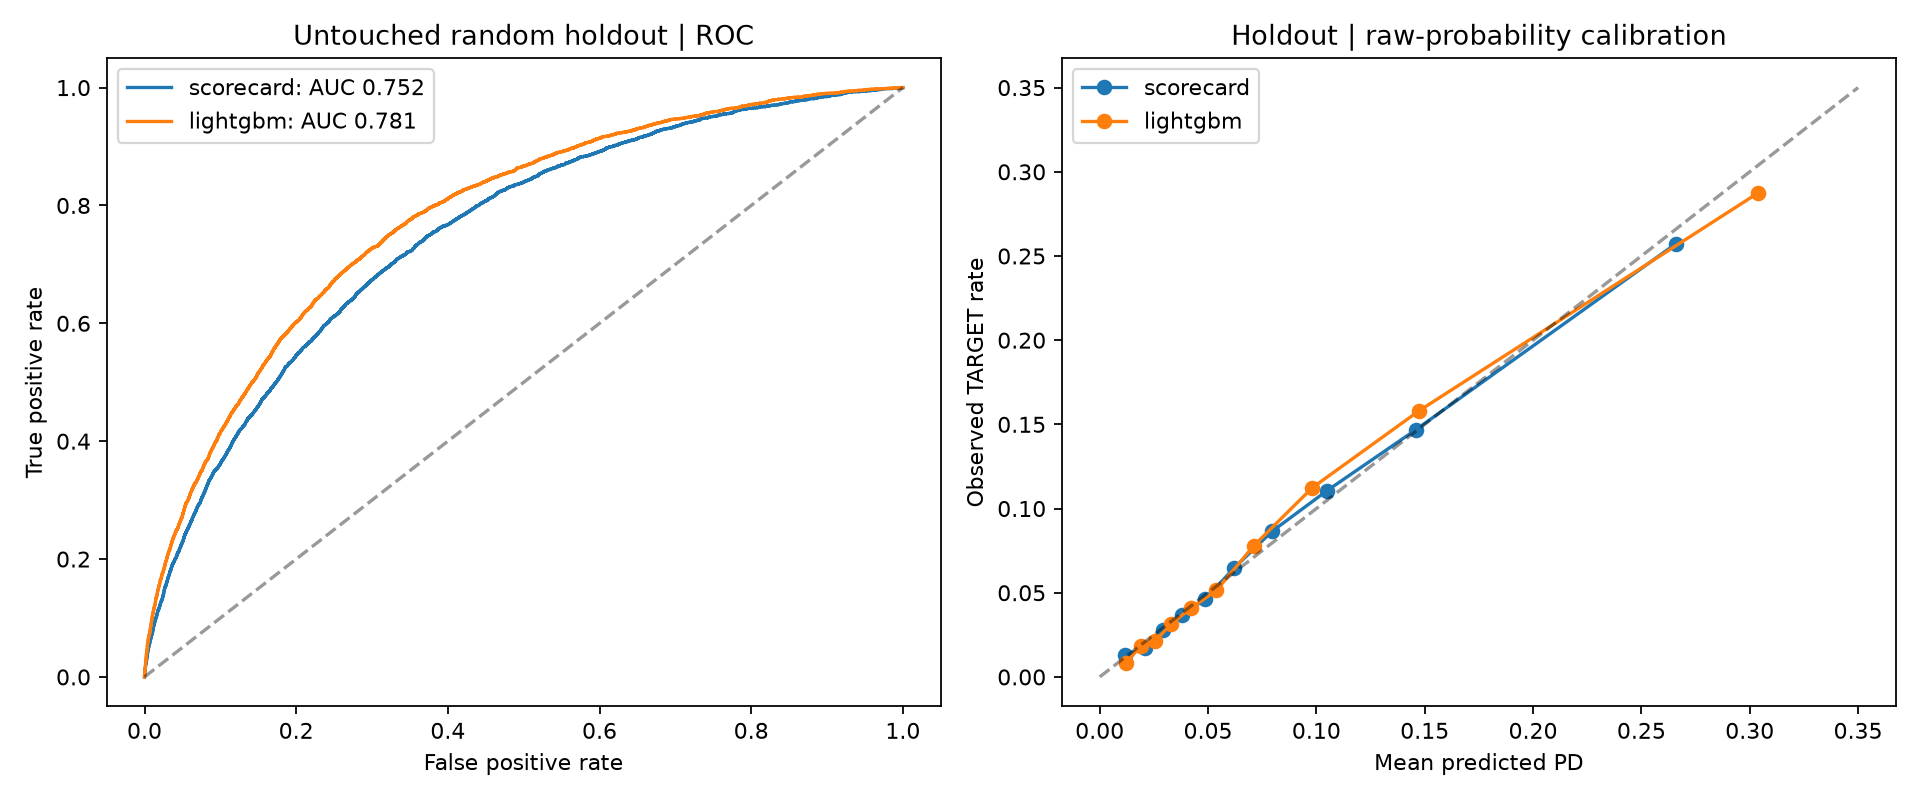

In [2]:
for model,splits in metrics['validation'].items():
    print(model)
    display(pd.DataFrame(splits).T)
display(pd.read_csv(ROOT/'reports/gains_scorecard_holdout.csv'))
print(json.dumps(metrics['score_psi'],indent=2))
print(json.dumps(metrics['key_feature_psi'],indent=2))
print(json.dumps(metrics['holdout_auc_bootstrap_95pct'],indent=2))
display(Image(filename=str(ROOT/'reports/figures/validation.png')))

## Interpretation

Gini = 2 x AUC - 1. KS is computed over all ROC thresholds; decile KS may be lower.
Calibration curves and Brier scores assess probability quality without fitting a
calibrator. PSI compares training-defined buckets with missing and half-count smoothing.
Heuristics: <0.1 stable, 0.1-0.25 moderate, >0.25 shifted. Random-split stability is not
time stability. Bootstrap intervals condition on the fitted models.